# Day 5 — Explainability Engine (Layer 5, Week 7)

Explaining the Day-4 funding predictions: **which real features** push the funding
probability up or down, globally and per-campaign, in technical and founder-readable
form. This notebook is a thin narrative — all logic lives in `src/explainability/` and
`src/copilot/`; here we import those modules and run them end to end.

**Two models, two tools** · base LightGBM → SHAP (black-box) · logistic regression →
coefficients (white-box). **Honesty rule:** explanations cite only real features
(campaign metadata + title tokens) and are framed as *learned associations, not causes*.

In [1]:
import sys, os, json, warnings, logging
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir(os.path.abspath(".."))
sys.path.insert(0, os.getcwd())
warnings.filterwarnings("ignore"); logging.disable(logging.WARNING)
import numpy as np, pandas as pd
from IPython.display import Image, display
print("cwd:", os.getcwd())

cwd: /Users/Yash/AI-Ventutre-Intelligence-Platform


## Phase A — Understanding Explainable AI

| | White-box (LogReg) | Black-box (LightGBM) |
|---|---|---|
| How to read | coefficients directly | post-hoc SHAP |
| PR-AUC here | 0.626 | **0.688** |

We deployed the **accurate** model and recover interpretability *post-hoc* with SHAP —
not by trading accuracy for a readable model. **Global** = "what drives funding overall",
**local** = "why this campaign". Full notes: `docs/day5_phaseA_explainability_notes.md`.

## Phase B — Global Feature Importance

`GlobalImportanceAnalyzer` ranks all 865 features by **gain**, **split**, and
**mean|SHAP|** (interventional — the default fast TreeSHAP is numerically broken for this
model, caught by an additivity assertion). Text vs tabular split is by *name membership*
(selection dropped `goal`, so a fixed index would be off-by-one). Loading the ranking the
module produced:

In [2]:
gi = pd.read_csv("artifacts/explainability/global_importance.csv")
print(f"{len(gi)} features = {(gi.group=='text').sum()} title tokens + {(gi.group=='tabular').sum()} tabular")
gi.sort_values("mean_abs_shap", ascending=False).head(10)[
    ["feature","group","gain_rank","split_rank","mean_abs_shap"]].reset_index(drop=True)

865 features = 800 title tokens + 65 tabular


,feature,group,gain_rank,split_rank,mean_abs_shap
0,usd_goal_real,tabular,1,4,0.320264
1,campaign_duration,tabular,3,5,0.262579
2,category_freq,tabular,2,1,0.221649
3,launch_year,tabular,5,6,0.201362
4,goal_per_day,tabular,4,3,0.149895
5,word_count,tabular,6,11,0.134060
6,title_length,tabular,8,8,0.111378
7,uppercase_ratio,tabular,7,2,0.105492
8,launch_weekday,tabular,14,10,0.063825
9,launch_month,tabular,12,9,0.058768


## Phase C — Logistic Regression Coefficients (mandatory Week 7)

White-box view. On StandardScaled features each coefficient is Δlog-odds per +1 SD;
`exp(coef)` is the odds multiplier. We also cross-check against the Phase-B SHAP ranking —
agreement across two model families = stronger evidence.

In [3]:
from src.explainability.coefficient_analysis import CoefficientAnalyzer
ca = CoefficientAnalyzer().load(); ca.compute()
print("cross-model agreement vs SHAP:", ca.agreement())
print("\nTop +coef (raise funding odds):")
display(ca.top_positive(6)[["feature","group","coef","odds_ratio"]].reset_index(drop=True))
print("Top -coef (lower funding odds):")
ca.top_negative(6)[["feature","group","coef","odds_ratio"]].reset_index(drop=True)

cross-model agreement vs SHAP: {'available': True, 'spearman': 0.4262, 'top_n': 20, 'overlap_count': 1, 'overlap_features': ['category_freq']}

Top +coef (raise funding odds):


,feature,group,coef,odds_ratio
0,category_freq,tabular,5.956343,386.195111
1,new record,text,2.116746,8.304071
2,miniature,text,2.050062,7.768381
3,burning man,text,1.956372,7.073615
4,thesis,text,1.908604,6.743671
5,titanium,text,1.787507,5.974537


Top -coef (lower funding odds):


,feature,group,coef,odds_ratio
0,youtube,text,-2.901520,0.054940
1,hip hop,text,-1.965281,0.140116
2,com,text,-1.635614,0.194833
3,website,text,-1.598019,0.202297
4,app,text,-1.573679,0.207281
5,network,text,-1.558791,0.210390


## Phase D — SHAP Engine + the additivity guard

`SHAPExplainer` builds an **interventional** TreeSHAP explainer once (fixed background),
then explains any rows. We build the full `ExplainabilityPipeline` here — it wires one
warm SHAP engine into the readable generator and the copilot (used for Phases E–I) — and
verify additivity: `base + Σshap ≈ model margin`.

In [4]:
from src.explainability.pipeline import ExplainabilityPipeline
pipe = ExplainabilityPipeline()          # one shared warm SHAP engine for all phases below

# one-row local explanation proves additivity holds (~1e-8)
import scipy.sparse as sp
Xtr = sp.load_npz("artifacts/fused_features/X_train_selected.npz").tocsr()
res = pipe.explainer.shap.explain(Xtr[123].toarray())
print(f"base={res.base_value:+.4f}  additivity error={res.additivity_error:.2e}  (SHAP explains the log-odds margin)")

base=-0.6985  additivity error=2.08e-08  (SHAP explains the log-odds margin)


## Phase E — Local Explanation (why *this* campaign)

Pick two contrasting real campaigns and show the top ± **real-feature** contributions.
Every factor is campaign metadata or a title word — never founder/market/revenue.

In [5]:
feat = ["name","category","main_category","currency","deadline","goal","launched","country","usd_goal_real","name_clean"]
df = pd.read_csv("data/processed/kickstarter_processed.csv")
sample = df.sample(60, random_state=7).reset_index(drop=True)
reports = pipe.explain(sample[feat])                 # one shared SHAP pass for the batch
probs = np.array([r.funding_probability for r in reports])
hi, lo = reports[int(probs.argmax())], reports[int(probs.argmin())]

def show(r, tag):
    print(f"=== {tag}: p={r.funding_probability:.3f} -> {r.predicted_label} (thr {r.decision_threshold}) ===")
    print("  + up  :", [(c['feature'], round(c['contribution'],3)) for c in r.local_explanation['top_positive'][:4]])
    print("  - down:", [(c['feature'], round(c['contribution'],3)) for c in r.local_explanation['top_negative'][:4]])
show(hi, "HIGH prob"); show(lo, "LOW prob")

=== HIGH prob: p=0.877 -> successful (thr 0.329) ===
  + up  : [('main_category_Theater', 0.738), ('fringe', 0.483), ('usd_goal_real', 0.466), ('campaign_duration', 0.415)]
  - down: [('launch_year', -0.301), ('title_length', -0.094), ('word_count', -0.089), ('currency_USD', -0.054)]
=== LOW prob: p=0.040 -> failed (thr 0.329) ===
  + up  : [('main_category_Theater', 0.443), ('launch_month', 0.043), ('simple', 0.036), ('currency_EUR', 0.019)]
  - down: [('usd_goal_real', -1.087), ('goal_per_day', -0.36), ('life', -0.337), ('uppercase_ratio', -0.27)]


## Phase F — Visualizations (mandatory Week 7)

`ExplainabilityVisualizer` renders 6 PNGs from the persisted artifacts. The **beeswarm**
(direction + spread per feature) and the **waterfall** (one campaign's additive
decomposition) are the two that carry the most signal.

rendered: ['shap_importance.png', 'tabular_importance.png', 'tfidf_importance.png', 'coefficient_plot.png', 'shap_summary.png', 'shap_waterfall.png']


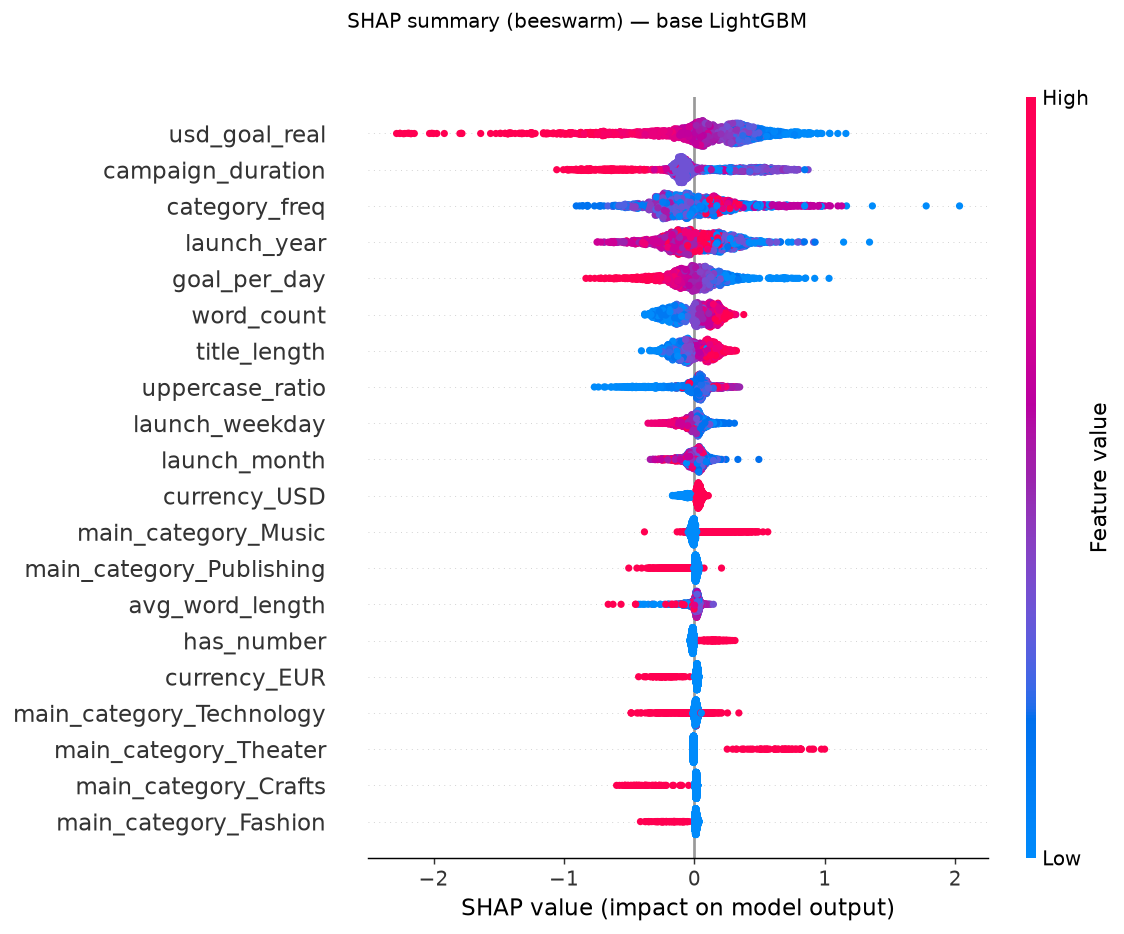

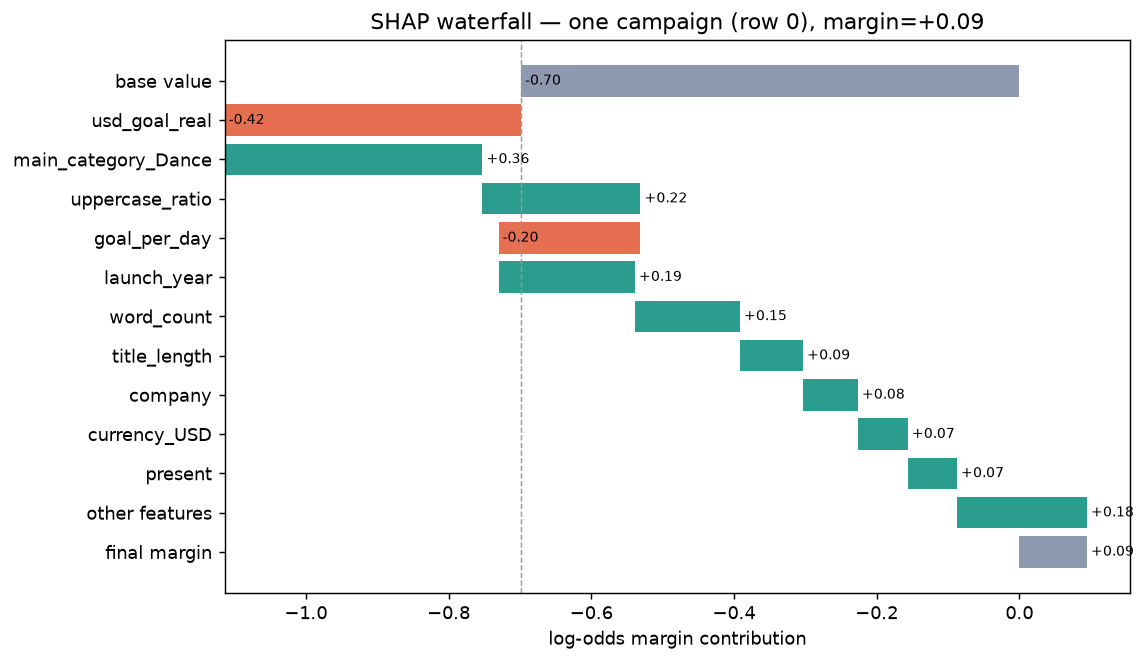

In [6]:
from src.explainability.visualization import ExplainabilityVisualizer
paths = ExplainabilityVisualizer().generate_all()
print("rendered:", [p.name for p in paths.values()])
display(Image(filename=str(paths["shap_summary"])))
display(Image(filename=str(paths["shap_waterfall"])))

## Phase G — Human-readable Explanation

`ExplanationGenerator` maps SHAP contributions to founder-facing sentences via a
readable-label map (`usd_goal_real` → "a large/modest funding goal"), respecting one-hot
direction and ending with an honesty caption.

In [7]:
# reuse the same explanations (no recompute) — render the high-prob campaign
exp_hi = pipe.explainer.explain_raw(sample[feat].iloc[[int(probs.argmax())]])[0]
print(pipe.generator.render(exp_hi))

This campaign is predicted successful, with a 88% chance of funding.
Factors raising its odds: being a Theater project; the title term 'fringe'; a modest funding goal; a short campaign length.
Factors lowering its odds: a recent launch year; a short title length; a low title word count; not raising funds in USD.
Note: these are patterns the model learned to associate with funding from campaign metadata and title text — not guaranteed causes of success.


## Phase H — Venture Copilot (honesty tiers)

**Generated** (grounded in real SHAP): Strengths / Weaknesses / Risks + score
explanations. **Deferred** (no data — never fabricated): market / competitor / founder /
opportunities.

In [8]:
brief = pipe.copilot.brief(exp_hi)
print(brief.headline)
print("STRENGTHS :", brief.strengths)
print("WEAKNESSES:", brief.weaknesses)
print("RISKS     :", brief.risks[0])
print("DEFERRED  :", {k: v['status'] for k, v in brief.deferred.items()})

High investment readiness — 88% modeled funding chance (successful).
STRENGTHS : ['Being a Theater project', "The title term 'fringe'", 'A modest funding goal', 'A short campaign length']
WEAKNESSES: ['A recent launch year', 'A short title length', 'A low title word count', 'Not raising funds in USD']
RISKS     : Modeled funding risk: 12% chance this campaign does not fund.
DEFERRED  : {'market_analysis': 'deferred', 'competitor_analysis': 'deferred', 'founder_intelligence': 'deferred', 'market_opportunities': 'deferred'}


## Phase I — Explainability Pipeline (single entry point)

`ExplainabilityPipeline.explain(raw)` returns the full bundle (prediction · scores ·
local · readable · copilot brief) in **one shared SHAP pass**, and `global_context()`
serves the model-level view — all inheriting Day-4 train/serve consistency.

In [9]:
r = reports[int(probs.argmax())]
print("bundle keys:", list(r.to_dict().keys()))
print("prediction :", r.funding_probability, r.predicted_label, "| additivity:", f"{r.meta['shap_additivity_error']:.1e}")
print("derived score  :", r.scores['startup_score'])
print("deferred score :", r.scores['founder_strength']['status'])
gc = pipe.global_context(top_k=5)
print("\nglobal top SHAP:", [d['feature'] for d in gc['top_shap_features']])
print("global top +coef:", [d['feature'] for d in gc['top_positive_coef']])

bundle keys: ['funding_probability', 'predicted_label', 'decision_threshold', 'scores', 'local_explanation', 'readable', 'brief', 'meta']
prediction : 0.8769 successful | additivity: 4.0e-08
derived score  : {'value': 88, 'scale': '0-100', 'status': 'derived', 'basis': '100 * funding_probability'}
deferred score : deferred

global top SHAP: ['usd_goal_real', 'campaign_duration', 'category_freq', 'launch_year', 'goal_per_day']
global top +coef: ['category_freq', 'new record', 'miniature', 'burning man', 'thesis']


## Day 5 complete — Week 7 ✅

Layer 5 Explainability Engine: global importance (gain/split/SHAP) · LogReg coefficients ·
interventional SHAP engine (additivity-guarded) · local explanations · 6 visualizations ·
readable generator · honesty-tiered Venture Copilot · explain-once pipeline. Every
explanation cites only real features and is framed as a learned association, not a cause.